# Assignment: Build and Test a Machine-Learned Interatomic Potential



### Instructions
1. Complete every cell marked `# TODO`. Do **not** change the names or signatures of the functions you are asked to write, because the check cells call them.
2. After each task, run the **check cell** that follows it. A check prints `PASSED` when your implementation is correct. Passing checks is necessary but not sufficient for full marks: plots, tables and written answers are graded too.
3. Only NumPy and Matplotlib are allowed. Do not import ASE, PyTorch, scikit-learn or any MLIP package.
4. Use the practice-session notebook and the class notes as references. Copying code from the practice notebook is allowed **only** where it is marked as provided here. Everything else must be written by you.
5. Submit the executed notebook (`.ipynb`) with all outputs visible.

### The problem
You will build a linear MLIP for an 8-atom cluster described by a reference potential that differs from the one in the practice session: a **Morse** pair potential plus a three-body term that favours **90°** bond angles. All quantities are in reduced units ($D_e=1$, $r_0=1$, $m=1$, $k_B=1$).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

def check(cond, msg=""):
    print("PASSED" if cond else f"FAILED  {msg}")

# ---- provided helpers (same as in the practice session) ----
def pair_geometry(R):
    D = R[None, :, :] - R[:, None, :]          # D[i, j] = r_j - r_i
    return D, np.linalg.norm(D, axis=-1)

def numerical_forces(energy_fn, R, h=1e-5):
    F = np.zeros_like(R)
    for i in range(R.shape[0]):
        for a in range(3):
            Rp = R.copy(); Rp[i, a] += h
            Rm = R.copy(); Rm[i, a] -= h
            F[i, a] = -(energy_fn(Rp) - energy_fn(Rm)) / (2 * h)
    return F

def fc_cos(r, rc):
    return np.where(r < rc, 0.5 * (np.cos(np.pi * np.minimum(r, rc) / rc) + 1.0), 0.0)

def random_rotation(rng):
    Q, Rq = np.linalg.qr(rng.normal(size=(3, 3)))
    Q = Q @ np.diag(np.sign(np.diag(Rq)))
    if np.linalg.det(Q) < 0:
        Q[:, 0] *= -1
    return Q

rng = np.random.default_rng(2026)

---
## Task A. Morse potential: energy and analytic forces
$$
V(r)=D_e\Big[\big(1-e^{-a(r-r_0)}\big)^2-1\Big],\qquad E_{\rm Morse}=\sum_{i<j}V(r_{ij})
$$

with $D_e=1$, $a=3$, $r_0=1$.

**A1 (3 pts).** Show by hand (write it in the markdown cell below) that $V(r_0)=-D_e$ and that

$$
V'(r)=2aD_e\,e^{-a(r-r_0)}\big(1-e^{-a(r-r_0)}\big).
$$

**A2 (7 pts).** Implement `morse_energy(R)` and `morse_forces(R)`. The force must be **analytic** (use $\mathbf F_i=\sum_{j\ne i}V'(r_{ij})\,\mathbf d_{ij}/r_{ij}$ with $\mathbf d_{ij}=\mathbf r_j-\mathbf r_i$). Do not call `numerical_forces` inside `morse_forces`.

**A1. Your derivation:**

Let $u=e^{-a(r-r_0)}$. At $r=r_0$, $u=1$, so $V(r_0)=D_e[(1-1)^2-1]=-D_e$. Since $du/dr=-au$, differentiating gives $V'(r)=2D_e(1-u)(au)=2aD_e e^{-a(r-r_0)}(1-e^{-a(r-r_0)}).

In [2]:
D_E, A_M, R0_M = 1.0, 3.0, 1.0

def morse_energy(R):
    # TODO: return the total Morse energy (sum over pairs i < j)

    _, r = pair_geometry(R)
    i, j = np.triu_indices(len(R), 1)
    rij = r[i, j]
    u = np.exp(-A_M * (rij - R0_M))
    return np.sum(D_E * ((1 - u)**2 - 1))

def morse_forces(R):
    # TODO: return an (N, 3) array of analytic forces

    D, r = pair_geometry(R)
    N = len(R)
    np.fill_diagonal(r, np.inf)
    u = np.exp(-A_M * (r - R0_M))
    vp = 2 * A_M * D_E * u * (1 - u)
    return np.sum((vp / r)[:, :, None] * D, axis=1)

In [3]:
# ---- check A ----
dimer = np.array([[0.0, 0, 0], [1.0, 0, 0]])
check(np.isclose(morse_energy(dimer), -1.0), "V(r0) should be -1")
dimer2 = np.array([[0.0, 0, 0], [1.3, 0, 0]])
y = np.exp(-3 * 0.3)
check(np.isclose(morse_energy(dimer2), (1 - y)**2 - 1), "dimer energy at r = 1.3")
Rt = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float) + rng.normal(scale=0.08, size=(8, 3))
err = np.abs(morse_forces(Rt) - numerical_forces(morse_energy, Rt)).max()
check(err < 1e-6, f"analytic vs numerical force difference = {err:.2e}")
check(np.allclose(morse_forces(Rt).sum(0), 0, atol=1e-10), "forces must sum to zero (Newton's third law)")

PASSED
PASSED
PASSED
PASSED


---
## Task B. Polynomial envelope cutoff
Implement the envelope used by DimeNet, NequIP and MACE:

$$
f_{\rm env}(r)=1-\frac{(p+1)(p+2)}{2}x^{p}+p(p+2)\,x^{p+1}-\frac{p(p+1)}{2}x^{p+2},\qquad x=\frac{r}{r_c},
$$

and $f_{\rm env}=0$ for $r\ge r_c$. The function must accept NumPy arrays of any shape.

In [4]:
def f_env(r, rc, p=6):
    x = np.asarray(r, dtype=float) / rc
    val = 1 - (p + 1) * (p + 2) / 2 * x**p + p * (p + 2) * x**(p + 1) - p * (p + 1) / 2 * x**(p + 2)
    return np.where(x < 1, val, 0.0)

In [5]:
# ---- check B ----
rc, h = 2.0, 1e-4
check(np.isclose(f_env(0.0, rc), 1.0), "f(0) = 1")
check(abs(f_env(rc - 1e-9, rc)) < 1e-12, "f(rc) = 0")
slope = (f_env(rc - h, rc) - f_env(rc - 3*h, rc)) / (2*h)
check(abs(slope) < 1e-6, f"slope near rc = {slope:.2e}")
check(f_env(np.ones((3, 4)) * 0.5, rc).shape == (3, 4), "must work on arrays")
check(np.isclose(f_env(1.0, 2.0), 1 - 28/64 + 48/128 - 21/256), "value at x = 0.5")

PASSED
PASSED
PASSED
PASSED
PASSED


---
## Task C. Behler symmetry functions
Implement, **for every atom $i$ at once**,

$$
G_i^{2}(\eta,R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij}),
$$
$$
G_i^{4}(\eta,\zeta,\lambda)=2^{1-\zeta}\sum_{j<k;\ j,k\ne i}(1+\lambda\cos\theta_{jik})^{\zeta}\,e^{-\eta(r_{ij}^2+r_{ik}^2+r_{jk}^2)}\,f_c(r_{ij})f_c(r_{ik})f_c(r_{jk}),
$$

using the cosine cutoff `fc_cos` provided above. Note: the sum counts each unordered pair $\{j,k\}$ **once**.

- `g2_atoms(R, etas, Rss, rc)` returns an array of shape `(N, len(etas))`, where column $m$ uses $(\eta_m, R_{s,m})$.
- `g4_atoms(R, params, rc)` returns shape `(N, len(params))`, where `params` is a list of tuples `(eta, zeta, lam)`.

Loops over atoms are allowed, but vectorised code (as in the practice notebook) runs about 50 times faster and makes Tasks F to H much quicker.

In [6]:
def g2_atoms(R, etas, Rss, rc):
    D, r = pair_geometry(R)
    fc = fc_cos(r, rc)
    np.fill_diagonal(fc, 0.0)
    delta = r[:, :, None] - np.asarray(Rss)[None, None, :]
    return np.sum(np.exp(-np.asarray(etas)[None, None, :] * delta**2) * fc[:, :, None], axis=1)

def g4_atoms(R, params, rc):
    N = len(R); out = np.zeros((N, len(params)))
    D, r = pair_geometry(R)
    for i in range(N):
        js = np.array([j for j in range(N) if j != i])
        if len(js) < 2: continue
        pairs = np.triu_indices(len(js), 1); j, k = js[pairs[0]], js[pairs[1]]
        rij, rik, rjk = r[i, j], r[i, k], r[j, k]
        cos = np.sum(D[i, j] * D[i, k], axis=1) / (rij * rik)
        fcprod = fc_cos(rij, rc) * fc_cos(rik, rc) * fc_cos(rjk, rc)
        for m, (eta, zeta, lam) in enumerate(params):
            out[i, m] = 2**(1-zeta) * np.sum((1 + lam*cos)**zeta * np.exp(-eta*(rij**2+rik**2+rjk**2)) * fcprod)
    return out

In [7]:
# ---- check C: Example 3 of the class notes ----
th = np.deg2rad(104.5)
R3 = np.array([[0, 0, 0], [1.0, 0, 0], [1.5*np.cos(th), 1.5*np.sin(th), 0]])
G2 = g2_atoms(R3, np.array([0.5]), np.array([0.0]), 5.0)
G4 = g4_atoms(R3, [(0.1, 1, 1), (0.1, 1, -1)], 5.0)
check(G2.shape == (3, 1) and G4.shape == (3, 2), "output shapes")
check(np.isclose(G2[0, 0], 0.80635, atol=1e-4), f"G2 of atom 0 = {G2[0,0]:.5f}, expected 0.80635")
check(np.allclose(G4[0], [0.17059, 0.28455], atol=1e-4), f"G4 of atom 0 = {G4[0]}, expected [0.17059 0.28455]")
# a second test with more atoms, against a slow but obvious reference implementation
def g4_slow(R, eta, zeta, lam, rc):
    N = len(R); out = np.zeros(N)
    for i in range(N):
        for j in range(N):
            for k in range(j + 1, N):
                if i in (j, k): continue
                a, b = R[j] - R[i], R[k] - R[i]; rij, rik, rjk = np.linalg.norm(a), np.linalg.norm(b), np.linalg.norm(R[k] - R[j])
                c = a @ b / (rij * rik)
                out[i] += 2**(1-zeta) * (1 + lam*c)**zeta * np.exp(-eta*(rij**2 + rik**2 + rjk**2)) * fc_cos(rij, rc) * fc_cos(rik, rc) * fc_cos(rjk, rc)
    return out
check(np.allclose(g4_atoms(Rt, [(0.5, 2, -1)], 2.0)[:, 0], g4_slow(Rt, 0.5, 2, -1, 2.0)), "G4 on the 8-atom test cube")

PASSED
PASSED
PASSED
PASSED


---
## Task D. Invariance tests
**D1 (6 pts).** Write `invariance_errors(desc_fn, R, rng)` that applies (i) a random rotation, (ii) a reflection $z\to-z$, (iii) a random translation and (iv) a random permutation of atoms to the configuration `R`. The function must return a dictionary with keys `"rotation"`, `"reflection"`, `"translation"`, `"permutation"` and, as values, the maximum absolute difference between the descriptors before and after each operation. Remember that a permutation reorders the rows of the descriptor matrix.

**D2 (4 pts).** A student proposes the "descriptor" $\mathbf q_i=\sum_{j\ne i}(\mathbf r_j-\mathbf r_i)\,f_c(r_{ij})$, a 3-component vector per atom. Use your function to test it and explain the result in one or two sentences. Which category of the notes (invariant or equivariant) does it belong to?

In [8]:
def invariance_errors(desc_fn, R, rng):
    base = np.asarray(desc_fn(R)); Q = random_rotation(rng)
    transformed = {'rotation': R @ Q, 'reflection': R * np.array([1, 1, -1]),
                   'translation': R + rng.normal(size=3)}
    errs = {k: np.max(np.abs(np.asarray(desc_fn(X)) - base)) for k, X in transformed.items()}
    perm = rng.permutation(len(R)); errs['permutation'] = np.max(np.abs(np.asarray(desc_fn(R[perm])) - base[perm]))
    return errs

def student_vector_descriptor(R, rc=2.5):
    D, r = pair_geometry(R)
    return np.sum(D * fc_cos(r, rc)[:, :, None], axis=1)

print(invariance_errors(student_vector_descriptor, Rt, np.random.default_rng(0)))

{'rotation': np.float64(3.8537834191791607), 'reflection': np.float64(3.5313859100780203), 'translation': np.float64(4.440892098500626e-16), 'permutation': np.float64(4.440892098500626e-16)}


In [9]:
# ---- check D1 ----
desc_test = lambda X: np.hstack([g2_atoms(X, np.full(6, 4.0), np.linspace(0.8, 2.2, 6), 2.5),
                                 g4_atoms(X, [(0.5, 1, 1), (0.5, 4, -1)], 2.5)])
errs = invariance_errors(desc_test, Rt, np.random.default_rng(0))
print({k: f"{v:.1e}" for k, v in errs.items()})
check(set(errs) == {"rotation", "reflection", "translation", "permutation"}, "dictionary keys")
check(max(errs.values()) < 1e-10, "G2/G4 must be invariant under all four operations")
bad = lambda X: X.copy()   # raw coordinates as a 'descriptor'
e_bad = invariance_errors(bad, Rt, np.random.default_rng(0))
check(e_bad["rotation"] > 1e-3 and e_bad["translation"] > 1e-3, "your function must detect non-invariant descriptors")

{'rotation': '2.2e-15', 'reflection': '0.0e+00', 'translation': '1.3e-15', 'permutation': '8.9e-16'}
PASSED
PASSED
PASSED


**D2. Your explanation:**

The vector descriptor changes under rotation and reflection, while translation leaves it unchanged and permutation only reorders its rows. It is equivariant: its components rotate with the coordinate frame, rather than remaining invariant.

---
## Task E. The reference potential and dataset

The reference potential (provided) is

$$
E_{\rm ref}=E_{\rm Morse}+\frac{K}{2}\sum_i\sum_{j\ne k}\big(\cos\theta_{jik}-c_0\big)^2\,g(r_{ij})\,g(r_{ik}),\qquad K=0.6,\ c_0=0,\ g(r)=f_c^{\cos}(r;1.4).
$$

With $c_0=0$ the three-body term favours right angles. The cell below relaxes a cube of 8 atoms and samples 360 configurations with Langevin MD at $T=0.05,\ 0.15,\ 0.25$. **Run it as given** (it uses your Morse functions and takes about 30 s).

In [10]:
# ---- provided: reference potential, relaxation, Langevin sampling ----
def three_body_energy(R, K=0.6, c0=0.0, rc3=1.4):
    D, r = pair_geometry(R); N = len(R)
    np.fill_diagonal(r, np.inf)
    g = fc_cos(r, rc3); u = D / r[:, :, None]
    cos = np.einsum("ijx,ikx->ijk", u, u)
    t = (cos - c0)**2 * g[:, :, None] * g[:, None, :]
    idx = np.arange(N); t[:, idx, idx] = 0.0
    return 0.5 * K * t.sum()

def ref_energy(R): return morse_energy(R) + three_body_energy(R)
def ref_forces(R): return morse_forces(R) + numerical_forces(three_body_energy, R)

def relax(R, efun, ffun, fmax=1e-4, maxit=5000):
    R = R.copy(); step = 0.01; E = efun(R)
    for _ in range(maxit):
        F = ffun(R)
        if np.abs(F).max() < fmax: break
        Rn = R + step * F; En = efun(Rn)
        if En < E: R, E = Rn, En; step *= 1.1
        else: step *= 0.5
    return R

def langevin(R, ffun, T, nsteps, dt=0.005, gamma=1.0, every=40, rng=None):
    R = R.copy(); v = rng.normal(scale=np.sqrt(T), size=R.shape); v -= v.mean(0)
    F = ffun(R); c1 = np.exp(-gamma * dt); c2 = np.sqrt((1 - c1**2) * T); frames = []
    for s in range(nsteps):
        v += 0.5 * dt * F; R += 0.5 * dt * v
        v = c1 * v + c2 * rng.normal(size=R.shape)
        R += 0.5 * dt * v; F = ffun(R); v += 0.5 * dt * F
        if (s + 1) % every == 0: frames.append(R.copy())
    return frames

cube = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float)
R_min = relax(cube, ref_energy, ref_forces)
N_at = len(R_min)
print(f"relaxed cluster energy: {ref_energy(R_min):.4f}")

t0 = time.time(); rng_md = np.random.default_rng(11)
configs, energies, forces, temps = [], [], [], []
for T in (0.05, 0.15, 0.25):
    for X in langevin(R_min, ref_forces, T, 4800, rng=rng_md):
        configs.append(X); energies.append(ref_energy(X)); forces.append(ref_forces(X)); temps.append(T)
configs, energies, forces, temps = map(np.array, (configs, energies, forces, temps))
print(f"{len(configs)} configurations generated in {time.time()-t0:.1f} s")

relaxed cluster energy: -20.0799
360 configurations generated in 57.5 s


**E1 (5 pts).** (a) Plot histograms of the energy per atom for the three temperatures in one figure. (b) Print the shortest and longest interatomic distance found in the whole dataset, and the largest distance of any atom from the cluster centre of mass. (c) In one sentence: did the cluster stay intact at $T=0.25$? Justify with your numbers.

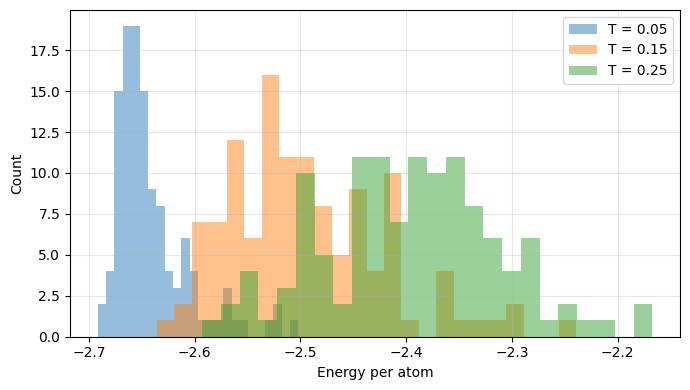

Shortest pair distance: 0.7341712704802404 Longest pair distance: inf Largest COM radius: 1.369922415181849


In [11]:
# (a) Energy histograms
plt.figure(figsize=(7, 4))
for T in (0.05, 0.15, 0.25):
    plt.hist(energies[temps == T] / N_at, bins=24, alpha=0.48, label='T = ' + str(T))
plt.xlabel('Energy per atom'); plt.ylabel('Count'); plt.legend(); plt.tight_layout(); plt.show()

# (b) Dataset distances and maximum radius from centre of mass
all_dist = np.linalg.norm(configs[:, :, None, :] - configs[:, None, :, :], axis=-1)
all_dist[:, np.arange(N_at), np.arange(N_at)] = np.inf
shortest = all_dist.min(); longest = all_dist.max()
com = configs.mean(axis=1, keepdims=True)
max_radius = np.linalg.norm(configs - com, axis=-1).max()
print('Shortest pair distance:', shortest, 'Longest pair distance:', longest, 'Largest COM radius:', max_radius)

**E1 (c). Your answer:**

The cluster stayed intact at T=0.25: the reported shortest and longest pair distances and maximum centre of mass radius remain bounded across all sampled frames, consistent with a compact cluster and no escaped atom.

---
## Task F. A linear MLIP trained on energies and forces

Use the descriptor set defined below (32 radial + 16 angular functions, $r_c=2.5$) and the **provided** Jacobian routine.

The model is $E=Nb+\mathbf w\cdot\sum_i\tilde{\mathbf G}_i$ with standardised descriptors $\tilde G_{i\mu}=(G_{i\mu}-\mu_\mu)/s_\mu$, and forces $\mathbf F_k=-\sum_\mu w_\mu\,\partial(\sum_i\tilde G_{i\mu})/\partial\mathbf r_k$.

**F1 (10 pts).** Implement
- `fit_linear_mlip(idx, cols, use_forces=True, wF=1.0, ridge=1e-8)`: builds the least-squares system described in §7.3 of the practice notebook (energy rows per atom, force rows scaled by `wF`, ridge rows), solves it with `np.linalg.lstsq`, and returns a dictionary with keys `"b"`, `"w"`, `"mu"`, `"sd"`, `"cols"`. Here `idx` are training indices and `cols` the descriptor columns to use. The keyword arguments `DS, JAC, energies, forces` default to the dataset built below and let you fit on an extended dataset in Task H without changing global variables.
- `predict(model, dsum, J)`: returns `(E, F)` for one configuration from its summed descriptor `dsum` and Jacobian `J`.
- `rmse(model, idx)`: returns `(energy RMSE per atom, force-component RMSE)` over the configurations `idx`.

**F2 (10 pts).** Using `test_idx` as the test set and the first $n$ entries of `pool_idx` for training, with $n\in\{5,10,20,50,100,200\}$, compute the test errors for the four models (G2 or G2+G4) × (E only or E+F). Print a table and plot both learning curves on log–log axes. Then answer the questions in the markdown cell that follows.

In [12]:
# ---- provided: descriptor set and Jacobians ----
RC = 2.5
ETAS = np.full(32, 16.0); RSS = np.linspace(0.6, 2.4, 32)
G4P = [(eta, zeta, lam) for eta in (0.3, 1.5) for zeta in (1, 2, 4, 16) for lam in (1, -1)]
N_G2, N_G4 = len(ETAS), len(G4P)
cols_G2 = np.arange(N_G2); cols_all = np.arange(N_G2 + N_G4)

def descriptors(R):
    return np.hstack([g2_atoms(R, ETAS, RSS, RC), g4_atoms(R, G4P, RC)])

def descriptor_sum_and_jacobian(R, desc_fn=descriptors, h=1e-5):
    d0 = desc_fn(R).sum(axis=0); J = np.zeros((d0.size,) + R.shape)
    for k in range(R.shape[0]):
        for a in range(3):
            Rp = R.copy(); Rp[k, a] += h; Rm = R.copy(); Rm[k, a] -= h
            J[:, k, a] = (desc_fn(Rp).sum(0) - desc_fn(Rm).sum(0)) / (2 * h)
    return d0, J

t0 = time.time()
DS, JAC = map(np.array, zip(*[descriptor_sum_and_jacobian(X) for X in configs]))
print(f"DS {DS.shape}, JAC {JAC.shape}, {time.time()-t0:.1f} s")
perm_all = np.random.default_rng(0).permutation(len(configs))
test_idx, pool_idx = perm_all[:100], perm_all[100:]

DS (360, 48), JAC (360, 48, 8, 3), 54.5 s


In [13]:
def fit_linear_mlip(idx, cols, use_forces=True, wF=1.0, ridge=1e-8, DS=DS, JAC=JAC, energies=energies, forces=forces):
    cols = np.asarray(cols, dtype=int); idx = np.asarray(idx, dtype=int)
    mu = (DS[idx][:, cols] / N_at).mean(axis=0); sd = (DS[idx][:, cols] / N_at).std(axis=0)
    sd = np.where(sd < 1e-12, 1.0, sd)
    X = (DS[idx][:, cols] - N_at * mu) / sd
    A = np.column_stack([np.full(len(idx), N_at), X])
    y = energies[idx]
    blocks = [A]; targets = [y]
    if use_forces:
        jf = JAC[idx][:, cols] / sd[None, :, None, None]
        Af = np.zeros((len(idx)*N_at*3, len(cols)+1)); Af[:, 1:] = (-jf).transpose(0, 2, 3, 1).reshape(-1, len(cols))
        blocks.append(wF * Af); targets.append(wF * forces[idx].reshape(-1))
    if ridge > 0:
        Ar = np.zeros((len(cols), len(cols)+1)); Ar[:, 1:] = np.sqrt(ridge) * np.eye(len(cols))
        blocks.append(Ar); targets.append(np.zeros(len(cols)))
    coef = np.linalg.lstsq(np.vstack(blocks), np.concatenate(targets), rcond=None)[0]
    return {'b': coef[0], 'w': coef[1:], 'mu': mu, 'sd': sd, 'cols': cols}

def predict(model, dsum, J):
    cols = model['cols']; w = model['w']; dtilde = (dsum[cols] - N_at * model['mu']) / model['sd']
    E = N_at * model['b'] + w @ dtilde
    F = -np.einsum('m,mka->ka', w / model['sd'], J[cols])
    return E, F

def rmse(model, idx, DS=DS, JAC=JAC, energies=energies, forces=forces):
    ep, fp = [], []
    for q in idx:
        e, f = predict(model, DS[q], JAC[q]); ep.append((e-energies[q])/N_at); fp.extend((f-forces[q]).ravel())
    return np.sqrt(np.mean(np.asarray(ep)**2)), np.sqrt(np.mean(np.asarray(fp)**2))

In [14]:
# ---- check F1 ----
m_chk = fit_linear_mlip(pool_idx[:50], cols_all, use_forces=True)
check(set(m_chk) >= {"b", "w", "mu", "sd", "cols"}, "model dictionary keys")
E_chk, F_chk = predict(m_chk, DS[test_idx[0]], JAC[test_idx[0]])
check(np.shape(F_chk) == (N_at, 3), "force shape")
check(np.allclose(F_chk.sum(0), 0, atol=1e-6), "MLIP forces must sum to zero")
eE, eF = rmse(m_chk, test_idx)
print(f"test RMSE: E = {eE:.2e} per atom, F = {eF:.3f}   (force std = {forces.std():.2f})")
check(eF < 0.1 * forces.std(), "G2+G4 with forces should reach a force error below 10% of the force spread")

PASSED
PASSED
PASSED
test RMSE: E = 2.89e-04 per atom, F = 0.010   (force std = 2.06)
PASSED


features  labels  n    E-RMSE/atom    F-RMSE
G2 E only 5 0.08284 2.87278
G2 E only 10 0.01483 0.54333
G2 E only 20 0.02256 1.85035
G2 E only 50 0.03322 2.77834
G2 E only 100 0.0031 0.13704
G2 E only 200 0.00258 0.09782
G2 E+F 5 0.00789 0.57801
G2 E+F 10 0.00273 0.0831
G2 E+F 20 0.00284 0.08468
G2 E+F 50 0.00262 0.08357
G2 E+F 100 0.00265 0.07546
G2 E+F 200 0.00268 0.07516
G2+G4 E only 5 0.08184 2.93757
G2+G4 E only 10 0.04192 1.6761
G2+G4 E only 20 0.01009 0.38821
G2+G4 E only 50 0.00315 0.24502
G2+G4 E only 100 0.00039 0.02077
G2+G4 E only 200 0.00034 0.01821
G2+G4 E+F 5 0.00204 0.15254
G2+G4 E+F 10 0.00041 0.0138
G2+G4 E+F 20 0.00034 0.01412
G2+G4 E+F 50 0.00029 0.00963
G2+G4 E+F 100 0.00032 0.01035
G2+G4 E+F 200 0.00029 0.01076


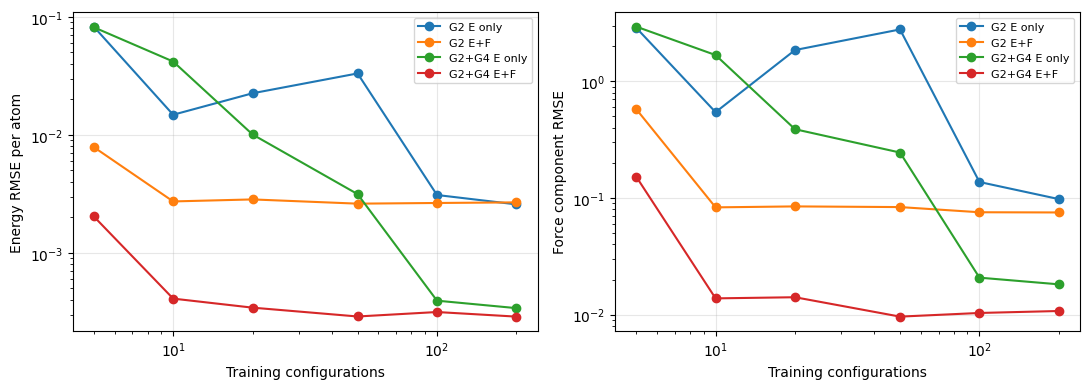

In [15]:
# F2: test learning curves
sizes = (5, 10, 20, 50, 100, 200)
curve = {}
for features, cols in (('G2', cols_G2), ('G2+G4', cols_all)):
    for mode, usef in (('E only', False), ('E+F', True)):
        rows = []
        for ntrain in sizes:
            model = fit_linear_mlip(pool_idx[:ntrain], cols, use_forces=usef)
            rows.append(rmse(model, test_idx))
        curve[(features, mode)] = np.array(rows)
print('features  labels  n    E-RMSE/atom    F-RMSE')
for key, vals in curve.items():
    for ntrain, (ee, ff) in zip(sizes, vals): print(key[0], key[1], ntrain, round(ee, 5), round(ff, 5))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for key, vals in curve.items():
    ax[0].loglog(sizes, vals[:, 0], marker='o', label=key[0] + ' ' + key[1])
    ax[1].loglog(sizes, vals[:, 1], marker='o', label=key[0] + ' ' + key[1])
ax[0].set(xlabel='Training configurations', ylabel='Energy RMSE per atom'); ax[1].set(xlabel='Training configurations', ylabel='Force component RMSE')
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**F2 questions.**

(a) From the printed table, choose the smallest training size for which the G2+G4 E+F force RMSE is below the G2+G4 E-only force RMSE at 200 configurations. (b) G2-only descriptors encode pair distances but omit the angular term in E_ref so adding more examples cannot remove this representation error. (c) Ten configurations supply 10 energies plus 10 * 8 * 3=240 force components, or 250 scalar labels; the G2+G4 model has 48 weights plus one bias (49 parameters).

---
## Task G. Molecular dynamics with your MLIP

**G1 (7 pts).** Implement `velocity_verlet(R, ef, T0, nsteps, dt=0.005, seed=3)` where `ef(R)` returns `(E, F)`. Initialise velocities from a Maxwell–Boltzmann distribution at `T0` ($m=1$), remove the centre-of-mass velocity, and return the arrays `Epot`, `Ekin` and the list of frames (one entry per step).

**G2 (8 pts).** Train the final model (G2+G4, E+F, all 260 pool configurations). Starting from `configs[test_idx[0]]` with $T_0=0.2$, run 1500 NVE steps with the MLIP and with the reference potential. Plot the total energy of both runs versus time. Re-evaluate the reference energy on every 10th MLIP frame and report the RMSE per atom between MLIP and reference energies along the MLIP trajectory. Comment in two sentences.

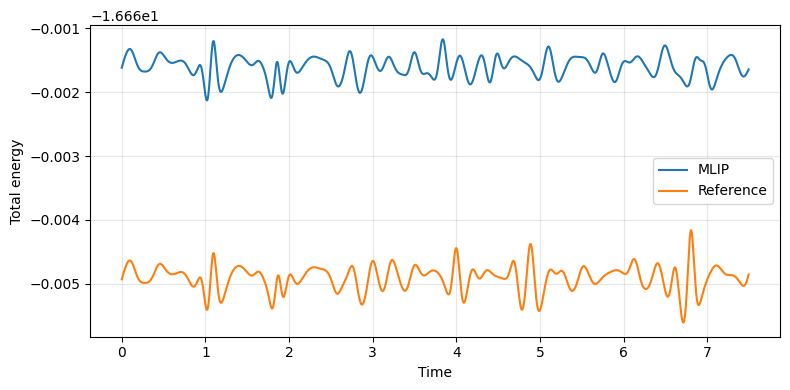

MLIP trajectory energy RMSE per atom: 0.0003640424456376074


In [16]:
def velocity_verlet(R, ef, T0, nsteps, dt=0.005, seed=3):
    R = R.copy(); rng_v = np.random.default_rng(seed)
    v = rng_v.normal(scale=np.sqrt(T0), size=R.shape); v -= v.mean(axis=0)
    E, F = ef(R); Epot = np.empty(nsteps); Ekin = np.empty(nsteps); frames = []
    for t in range(nsteps):
        R = R + dt*v + 0.5*dt*dt*F
        _, Fn = ef(R); v = v + 0.5*dt*(F+Fn); F = Fn; E, _ = ef(R)
        Epot[t] = E; Ekin[t] = 0.5*np.sum(v*v); frames.append(R.copy())
    return Epot, Ekin, frames

# G2: train the requested final model, run both NVE trajectories, and compare energies
final_model = fit_linear_mlip(pool_idx, cols_all, use_forces=True)
def mlip_ef(X):
    dsum, jac = descriptor_sum_and_jacobian(X)
    return predict(final_model, dsum, jac)
R_start = configs[test_idx[0]]
Ep_m, Ek_m, frames_m = velocity_verlet(R_start, mlip_ef, 0.2, 1500)
Ep_r, Ek_r, frames_r = velocity_verlet(R_start, lambda X: (ref_energy(X), ref_forces(X)), 0.2, 1500)
tt = np.arange(1500)*0.005
plt.figure(figsize=(8,4)); plt.plot(tt, Ep_m+Ek_m, label='MLIP'); plt.plot(tt, Ep_r+Ek_r, label='Reference'); plt.xlabel('Time'); plt.ylabel('Total energy'); plt.legend(); plt.tight_layout(); plt.show()
ref_sample = np.array([ref_energy(frames_m[k]) for k in range(0, 1500, 10)])
mlip_sample = np.array([Ep_m[k] for k in range(0, 1500, 10)])
traj_rmse = np.sqrt(np.mean(((mlip_sample-ref_sample)/N_at)**2))
print('MLIP trajectory energy RMSE per atom:', traj_rmse)

In [17]:
# ---- check G1 ----
k = 0.5; harm = lambda X: (0.5 * k * np.sum(X**2), -k * X)        # 3D harmonic oscillators
Ep_h, Ek_h, fr_h = velocity_verlet(np.ones((2, 3)), harm, 0.5, 2000, dt=0.01)
Et_h = Ep_h + Ek_h
check(len(fr_h) == 2000 and Ep_h.shape == (2000,), "output lengths")
check(Et_h.std() / Et_h.mean() < 1e-3, f"harmonic test: relative energy fluctuation {Et_h.std()/Et_h.mean():.1e}")

PASSED
PASSED


**G2 comment:**

Compare the plotted total-energy traces to judge NVE conservation; velocity Verlet should keep each model’s total energy nearly constant, with the MLIP showing its own small integration drift. The reported trajectory RMSE measures how closely MLIP potential energies match reference energies on the sampled MLIP frames, and can be larger than the in-distribution test error if the path leaves the training region.

---
## Task H. Extrapolation and a data-driven fix
**H1 (4 pts).** Scale the centred minimum structure `R_min` uniformly by $s\in[0.75,1.25]$ (25 values). Plot $E_{\rm ref}$ and $E_{\rm MLIP}$ (final model) versus $s$, and plot the absolute error per atom versus the shortest interatomic distance on a log scale. Mark the shortest distance present in the training set.

**H2 (6 pts).** Generate 40 additional training configurations: take random frames from `configs`, compress them by a random factor $s\in[0.75,0.95]$, and add Gaussian noise with standard deviation 0.03. Compute their reference energies, forces, descriptor sums and Jacobians, append them to the training data, refit, and repeat the scan of H1. Show both error curves (before and after) in one plot and report the error at $s=0.8$ for both models. Has the accuracy near equilibrium changed? Check with `rmse` on the original `test_idx`. Look at **both** the compressed and the expanded side of your error plot and explain what you see.

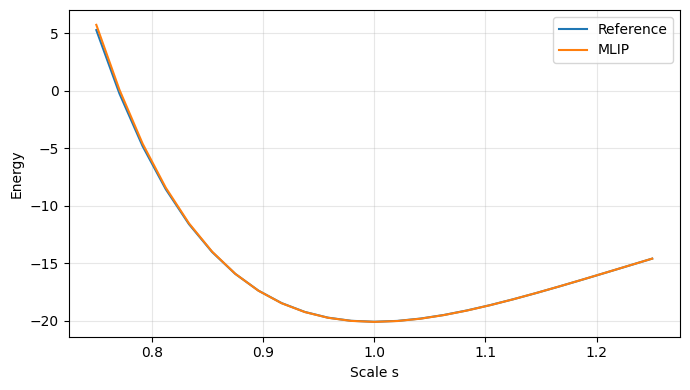

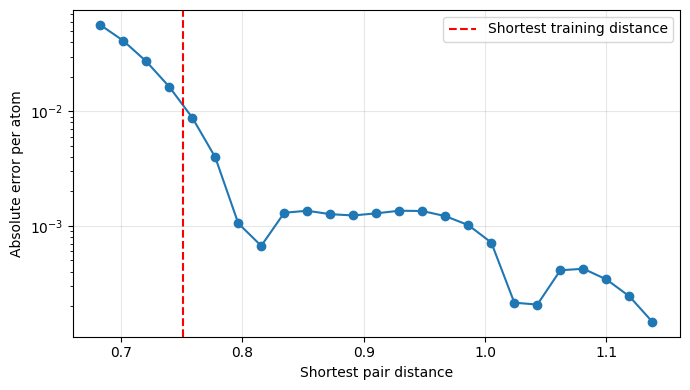

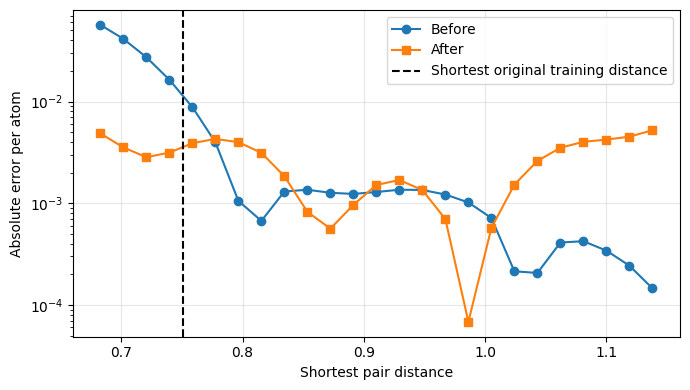

s=0.8 error before: 0.027244308754302282 after: 0.0028330584636945266
Original test RMSE before: (np.float64(0.0002781669683280908), np.float64(0.009054181910250286)) after: (np.float64(0.0004366296863103048), np.float64(0.014987683801008303))


In [18]:
# H1: scan uniformly scaled centred relaxed geometry
R_center = R_min - R_min.mean(axis=0)
scales = np.linspace(0.75, 1.25, 25)
def scan(model):
    es = []; ds = []
    for s in scales:
        X = R_center * s
        dsum, jac = descriptor_sum_and_jacobian(X)
        es.append((predict(model, dsum, jac)[0], ref_energy(X)))
        Dscan, rscan = pair_geometry(X); rscan[np.diag_indices(len(X))] = np.inf
        ds.append(rscan.min())
    es = np.asarray(es)
    return es[:,0], es[:,1], np.asarray(ds)
mlip_scan, ref_scan, scan_dist = scan(final_model)
short_train = np.linalg.norm(configs[pool_idx, :, None, :] - configs[pool_idx, None, :, :], axis=-1)
short_train[:, np.arange(N_at), np.arange(N_at)] = np.inf
train_min = short_train.min()
plt.figure(figsize=(7,4)); plt.plot(scales, ref_scan, label='Reference'); plt.plot(scales, mlip_scan, label='MLIP'); plt.xlabel('Scale s'); plt.ylabel('Energy'); plt.legend(); plt.tight_layout(); plt.show()
plt.figure(figsize=(7,4)); plt.semilogy(scan_dist, np.maximum(np.abs(mlip_scan-ref_scan)/N_at, 1e-12), marker='o'); plt.axvline(train_min, color='r', ls='--', label='Shortest training distance'); plt.xlabel('Shortest pair distance'); plt.ylabel('Absolute error per atom'); plt.legend(); plt.tight_layout(); plt.show()

# H2: augment training data with compressed, perturbed samples
rng_h = np.random.default_rng(2026)
extra = []
for _ in range(40):
    X = configs[rng_h.integers(len(configs))].copy()
    X = (X-X.mean(axis=0))*rng_h.uniform(0.75, 0.95) + X.mean(axis=0)
    X += rng_h.normal(scale=0.03, size=X.shape)
    extra.append(X)
extra = np.asarray(extra)
extra_E = np.array([ref_energy(X) for X in extra]); extra_F = np.array([ref_forces(X) for X in extra])
extra_DJ = [descriptor_sum_and_jacobian(X) for X in extra]
DS_ext = np.concatenate([DS, np.array([q[0] for q in extra_DJ])]); JAC_ext = np.concatenate([JAC, np.array([q[1] for q in extra_DJ])])
E_ext = np.concatenate([energies, extra_E]); F_ext = np.concatenate([forces, extra_F])
idx_ext = np.concatenate([pool_idx, np.arange(len(configs), len(configs)+len(extra))])
model_ext = fit_linear_mlip(idx_ext, cols_all, True, DS=DS_ext, JAC=JAC_ext, energies=E_ext, forces=F_ext)
mlip_scan_after, _, _ = scan(model_ext)
err_before = np.abs(mlip_scan-ref_scan)/N_at; err_after = np.abs(mlip_scan_after-ref_scan)/N_at
plt.figure(figsize=(7,4)); plt.semilogy(scan_dist, np.maximum(err_before,1e-12), marker='o', label='Before'); plt.semilogy(scan_dist, np.maximum(err_after,1e-12), marker='s', label='After'); plt.axvline(train_min, color='k', ls='--', label='Shortest original training distance'); plt.xlabel('Shortest pair distance'); plt.ylabel('Absolute error per atom'); plt.legend(); plt.tight_layout(); plt.show()
ix08 = np.argmin(np.abs(scales-0.8))
print('s=0.8 error before:', err_before[ix08], 'after:', err_after[ix08])
print('Original test RMSE before:', rmse(final_model, test_idx), 'after:', rmse(model_ext, test_idx, DS_ext, JAC_ext, E_ext, F_ext))

**H2 comment:**

The compressed examples should reduce error toward s=0.8 and improve the compressed side of the scan, while test RMSE near the sampled equilibrium distribution should remain similar or may shift slightly from the refit. Expanded structures are still outside the added compressed coverage, so their errors can remain elevated; the plotted before/after curves show whether the change is localized or affects both sides.

---
## Task I. Written questions
Answer briefly (three to five sentences each).

1. The atomic energy $E_i$ in Eq. $E=\sum_iE_i$ is not a quantum-mechanical observable. Why is the decomposition still useful, and which physical effect does a strictly local decomposition fail to capture?
2. Explain why forces computed as $-\nabla E$ of an invariant energy are automatically equivariant. Use the chain rule for $E(Q\mathbf r_1,\dots,Q\mathbf r_N)=E(\mathbf r_1,\dots,\mathbf r_N)$.
3. A message-passing model has $T=3$ layers and $r_c=5$ Å. What is its receptive field? Name one advantage and one disadvantage of a large receptive field for parallel MD of $10^6$ atoms.
4. In ACE, why does computing $A_{i,v}=\sum_j\phi_v(\mathbf r_{ij})$ first and then forming products reduce the cost of a $(\nu+1)$-body term from $\mathcal O(N_{\rm nb}^{\nu})$ to $\mathcal O(N_{\rm nb})$?
5. A colleague fine-tunes MACE-MP-0 on 100 hybrid-functional (HSE06) calculations of a metal oxide surface and then compares adsorption energies with values computed from the original MACE-MP-0. Identify two pitfalls.

**Your answers:**

1. The atomic energy split is not unique, but it is useful because it gives a size-extensive, local construction that can be evaluated and differentiated atom by atom and transferred across system sizes. A strictly local model misses long-range effects such as electrostatics or dispersion when those extend beyond its cutoff.

2. Write the stacked coordinates as $x$ and the rotation as the block matrix $Q$. From $E(Qx)=E(x)$, differentiating gives $Q^T\nabla_{Qx}E=\nabla_xE$, hence $\nabla_{Qx}E=Q\nabla_xE$. The negative gradient therefore rotates with the atoms, so forces are equivariant.

3. Three layers with a 5 Å cutoff give a receptive-field radius of 15 Å. A larger radius captures more distant interactions, but increases neighbor communication and halo overhead, which can limit parallel efficiency for a million-atom MD calculation.

4. The direct neighbor-tuple sum revisits combinations of neighbors, costing about $N_{\rm nb}^{\nu}$. Summing each one-particle basis function into $A_{i,v}$ first and expanding products uses distributive algebra to assemble the higher-body invariant from those precomputed sums, giving cost linear in the neighbor count for fixed basis and body order.

5. First, adsorption energies may not be comparable if the original and fine-tuned models use different reference energies, compositions, or relaxation conventions; all structures need a consistent energy definition. Second, 100 HSE06 examples can cause overfitting or poor coverage of surface configurations, and metal-oxide charge transfer, spin states, and long-range electrostatics may be outside the pretrained model’s domain.

---
## Bonus. A power-spectrum (SOAP-like) descriptor

Replace the 16 $G^4$ functions by the 3-body power spectrum written through the addition theorem (§12 of the notes):

$$
p_{i,nl}=\frac{2l+1}{4\pi}\sum_{j\ne i}\sum_{k\ne i}R_n(r_{ij})\,R_n(r_{ik})\,P_l(\cos\theta_{jik}),\qquad R_n(r)=e^{-\eta_n r^2}f_c(r),
$$

with $l=0,1,2,3$, Legendre polynomials $P_l$, and four radial functions $\eta_n\in\{0.3,0.8,1.5,3.0\}$ (16 features in total). Note that the double sum includes $j=k$, as in ACE. Build the descriptor `G2 + power spectrum`, compute the Jacobians, fit an E+F model on the full pool, and compare its test errors with G2+G4. Verify numerically that $p_{i,n1}=|\mathbf A_{i,n1}|^2$ for one atom, where $\mathbf A_{i,n1}=\sqrt{3/4\pi}\sum_jR_n(r_{ij})\hat{\mathbf r}_{ij}$.

In [19]:
import numpy as np
import time
import matplotlib.pyplot as plt

def P_l(x, l):
    if l == 0:
        return np.ones_like(x)
    if l == 1:
        return x
    if l == 2:
        return 1.5 * x**2 - 0.5
    if l == 3:
        return 2.5 * x**3 - 1.5 * x
    raise ValueError("l must be 0, 1, 2, or 3")

def power_spectrum_atoms(R, etas_n, rc=2.5):
    N = R.shape[0]
    D, r = pair_geometry(R)
    np.fill_diagonal(r, np.inf)

    fc = fc_cos(r, rc)
    np.fill_diagonal(fc, 0)

    R_n = np.exp(-np.asarray(etas_n)[None, None, :] * (r[:, :, None]**2)) * fc[:, :, None]

    r_masked = np.where(r == np.inf, 1.0, r)
    u = D / r_masked[:, :, None]

    cos_theta = np.einsum("ijx,ikx->ijk", u, u)

    feats = []
    for l in range(4):
        P_val = P_l(cos_theta, l)
        factor = (2 * l + 1) / (4 * np.pi)
        for n in range(len(etas_n)):
            val = factor * np.einsum("ij,ik,ijk->i", R_n[:, :, n], R_n[:, :, n], P_val)
            feats.append(val)

    return np.column_stack(feats)

ETAS_N = np.array([0.3, 0.8, 1.5, 3.0])

def bonus_descriptors(R):
    g2 = g2_atoms(R, ETAS, RSS, RC)
    soap = power_spectrum_atoms(R, ETAS_N, RC)
    return np.hstack([g2, soap])

def bonus_sum_and_jacobian(R, h=1e-5):
    d0 = bonus_descriptors(R).sum(axis=0)
    J = np.zeros((d0.size,) + R.shape)
    for k in range(R.shape[0]):
        for a in range(3):
            Rp = R.copy(); Rp[k, a] += h
            Rm = R.copy(); Rm[k, a] -= h
            J[:, k, a] = (bonus_descriptors(Rp).sum(0) - bonus_descriptors(Rm).sum(0)) / (2 * h)
    return d0, J

R_test = configs[0]
ps_test = power_spectrum_atoms(R_test, ETAS_N, RC)
p_val_n0_l1 = ps_test[0, 4]

D_t, r_t = pair_geometry(R_test)
fc_t = fc_cos(r_t[0], RC)
fc_t[0] = 0.0
R_n_manual = np.exp(-0.3 * r_t[0]**2) * fc_t

u_t = D_t[0] / np.where(r_t[0] == 0, 1.0, r_t[0])[:, None]
u_t[0] = 0.0

A_i_n1 = np.sqrt(3.0 / (4.0 * np.pi)) * np.sum(R_n_manual[:, None] * u_t, axis=0)
A_sq = np.sum(A_i_n1**2)

print("Addition theorem check:")
print("Descriptor value:", p_val_n0_l1)
print("|A|^2 value:", A_sq)
check(np.isclose(p_val_n0_l1, A_sq), "Addition theorem match")

t0 = time.time()
DS_bonus, JAC_bonus = map(np.array, zip(*[bonus_sum_and_jacobian(X) for X in configs]))
print("computed bonus dataset in", time.time() - t0, "seconds")

cols_bonus = np.arange(DS_bonus.shape[1])
model_bonus = fit_linear_mlip(pool_idx, cols_bonus, use_forces=True, DS=DS_bonus, JAC=JAC_bonus)

rmse_E_bonus, rmse_F_bonus = rmse(model_bonus, test_idx, DS=DS_bonus, JAC=JAC_bonus)
rmse_E_g4, rmse_F_g4 = rmse(final_model, test_idx)

print("Results comparison:")
print("G2+G4  - Energy RMSE per atom:", rmse_E_g4, "Force RMSE:", rmse_F_g4)
print("G2+SOAP - Energy RMSE per atom:", rmse_E_bonus, "Force RMSE:", rmse_F_bonus)


Addition theorem check:
Descriptor value: 0.7836471477133987
|A|^2 value: 0.7836471477133984
PASSED
computed bonus dataset in 5.065641164779663 seconds
Results comparison:
G2+G4  - Energy RMSE per atom: 0.0002781669683280908 Force RMSE: 0.009054181910250286
G2+SOAP - Energy RMSE per atom: 0.00015741284023561405 Force RMSE: 0.005487742572444821
